# [11.4] Concept Erasure

# Introduction

You remove a probe's direction. That probe now predicts nothing useful. Have
you removed the concept—or only broken one way of reading it?

We will construct four points for which this distinction is exact. You will
implement a closed-form eraser, compare it with an independent constrained
optimizer, and ask what its guarantee actually covers. Then we will erase a
name-role representation in frozen GPT-2 and inspect both its answers and an
unrelated object task. The useful result is a comparison of representations,
readouts and behavior, not a single “erasure score”.

## Content & Learning Objectives

### 1️⃣ Specify what “removed” means

> - Distinguish a disabled probe from a class of disabled predictors.
> - Relate class means to centered cross-covariance.
> - Keep convex probe loss separate from thresholded accuracy.

### 2️⃣ Derive the least-distorting affine edit

> - Whiten only directions with empirical variance.
> - Implement orthogonal removal and the LEACE oblique eraser.
> - Preserve the mean and compare with an independent optimization oracle.

### 3️⃣ Try to recover the information

> - Refit a probe after changing its inputs.
> - Exhibit nonlinear information that survives linear guardedness.
> - Separate fitting-set properties from new-data behavior.

### 4️⃣ Erase a role inside a real transformer

> - Fit the eraser and the evaluation probe on separate sentences.
> - Compare actual next-token answers with matched controls.
> - Measure representation distortion and unrelated-task damage.

## Setup

The exact examples run on CPU in seconds. Allow roughly 90 minutes to implement
and investigate them, followed by two hours for the transformer study. Complete
a function before running its immediate tests, or use its own solution dropdown
when you need help. PyTorch and plotting use the repository's `uv` environment.


In [1]:
import itertools
import json
import math
import os
import sys
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import torch as t
import torch.nn.functional as F
from IPython import get_ipython

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "chapter11_representation_geometry").exists())
if str(root_dir) not in sys.path:
    sys.path.append(str(root_dir))
from chapter11_representation_geometry.exercises.part4_concept_erasure import erasure_methods_tests as tests
assets_dir = Path(os.environ.get("ARENA_ERASURE_OUTPUT_DIRECTORY", "erasure_outputs"))
assets_dir.mkdir(parents=True, exist_ok=True)
t.set_num_threads(4)
plt.style.use("seaborn-v0_8-whitegrid")


# 1️⃣ What should an eraser remove?

## Four points, two variables

Let $U$ be an unrelated side variable taking values $-2$ and $2$, and let
$Z\in\{-1,1\}$ be the concept. Every combination occurs equally often. The
representation is $X=(U,U+Z)$. A linear readout recovers $Z$ exactly by subtracting
the first coordinate from the second.

Suppose you project away that readout's normal, $(-1,1)$. The edited points lie
on the line $x_1=x_2$, so the old subtraction returns zero. But the points are now
$(U+Z/2,U+Z/2)$: both coordinates still contain some of $Z$. We will measure that
remaining information rather than judging only the original probe.

An alternative target is to make every class centroid equal. With one-hot
labels, the $j$th column of the cross-covariance is

$$\operatorname{Cov}(X,1_{Z=j})=P(Z=j)\left(E[X\mid Z=j]-E[X]\right).$$

Thus zero cross-covariance equalizes the centroids. For affine predictors trained
with loss convex in their logits, Jensen's inequality then makes a constant
predictor optimal on this distribution. This is *linear guardedness* in the
[LEACE paper](https://proceedings.neurips.cc/paper_files/paper/2023/file/d066d21c619d0a78c5b557fa3291a8f4-Paper-Conference.pdf).
It is a claim about a predictor class, loss and distribution. It does not say
that the two class distributions are identical. We will build a counterexample.


### Exercise 1 — Compute the paired moments

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend 10–15 minutes on this exercise.
> ```

Return the two means, the population covariance of `x`, and its cross-covariance with `z`. Use denominator `n`, center both arrays, and preserve their dtype and device. For our binary example a single signed label column has the same removable span as centered two-column one-hot labels.

<details>
<summary>Help</summary>

Write `xc = x - x.mean(0)` and `zc = z - z.mean(0)`. Cross-covariance has shape `[representation_width, concept_width]`; it is not `zc.T @ xc`.

</details>

<details>
<summary>Expected output</summary>

For the four points, the covariance is `[[4, 4], [4, 5]]` and the signed-label cross-covariance is `[[0], [1]]`. Translating the representations changes the mean but neither covariance.

</details>

<details>
<summary>Solution</summary>

```python
def centered_statistics(x: t.Tensor, z: t.Tensor) -> dict:
    """Population second moments of paired rows, preserving their affine means."""
    if x.ndim != 2 or z.ndim != 2 or len(x) != len(z) or len(x) < 2:
        raise ValueError("Use at least two paired rows in X and Z.")
    if not x.is_floating_point() or not z.is_floating_point():
        raise ValueError("Use floating representations and floating one-hot labels.")
    if x.dtype != z.dtype or x.device != z.device or not x.shape[1] or not z.shape[1]:
        raise ValueError("Use nonempty features with matching dtype and device.")
    if not t.isfinite(x).all() or not t.isfinite(z).all():
        raise ValueError("Moments require finite data.")
    mean_x, mean_z = x.mean(0), z.mean(0)
    xc, zc = x - mean_x, z - mean_z
    return dict(mean_x=mean_x, mean_z=mean_z,
                covariance=xc.T @ xc / len(x), cross_covariance=xc.T @ zc / len(x))
```

</details>


In [ ]:
def centered_statistics(x: t.Tensor, z: t.Tensor) -> dict:
    """Population second moments of paired rows, preserving their affine means."""
    raise NotImplementedError()

tests.test_centered_moments(SimpleNamespace(**globals()))


In [3]:
u, concept = t.tensor(list(itertools.product((-2., 2.), (-1., 1.))), dtype=t.float64).T
points = t.stack((u, u + concept), 1)
concept_column = concept[:, None]
labels = (concept > 0).long()
old_normal = t.tensor([-1., 1.], dtype=t.float64)
old_normal /= old_normal.norm()
old_probe_erasure = dict(mean=points.mean(0), left=old_normal[:, None], right=old_normal[None], rank=1)
print("Every point (U, Z, x1, x2):")
for side, z, row in zip(u, concept, points):
    print(f"U={side:+.0f}, Z={z:+.0f}: ({row[0]:+.0f}, {row[1]:+.0f})")


Every point (U, Z, x1, x2):
U=-2, Z=-1: (-2, -3)
U=-2, Z=+1: (-2, -1)
U=+2, Z=-1: (+2, +1)
U=+2, Z=+1: (+2, +3)


# 2️⃣ Derive a small edit

## The constraint fixes the nullspace, not the destination

For an affine edit $r(x)=Px+b$, the erasure constraint is $P\Sigma_{XZ}=0$.
Orthogonally removing the column span of $\Sigma_{XZ}$ satisfies it. But this
only chooses one possible destination for the edited points.

In our example, the removable span is the second coordinate. Setting that
coordinate to zero loses both $Z$ and the useful contribution $U$. Replacing it
with the first coordinate also removes $Z$, but preserves $U$. Before computing
anything, predict the mean squared edit distance in those two cases.

Whitening will let us solve the general problem. In directions where empirical
variance is zero, there is nothing to rescale. Track that support explicitly;
blindly dividing by tiny eigenvalues can turn a small new-data difference into
a large intervention.


### Exercise 2 — Whiten the empirical support

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend 10–15 minutes on this exercise.
> ```

Diagonalize a symmetric positive-semidefinite covariance. Return whitening and unwhitening matrices, the numerical rank, eigenvalues and cutoff. By default use `width * machine_epsilon` as the relative eigenvalue cutoff. Reject materially negative or nonsymmetric inputs; tiny numerical negatives may be clipped.

<details>
<summary>Help</summary>

For an eigenvalue `s > cutoff`, use `1 / sqrt(s)` to whiten and `sqrt(s)` to unwhiten. Use zero in both matrices outside the retained support. Their product is the support projector, not necessarily the identity.

</details>

<details>
<summary>Expected output</summary>

For `diag([9, 1, 0])`, whitening is `diag([1/3, 1, 0])`, unwhitening is `diag([3, 1, 0])`, and the retained rank is two.

</details>

<details>
<summary>Solution</summary>

```python
def psd_whitener(covariance: t.Tensor, rcond: float | None = None) -> dict:
    """Whiten on the empirical support and preserve an explicit numerical rank."""
    if covariance.ndim != 2 or covariance.shape[0] != covariance.shape[1] or not len(covariance):
        raise ValueError("The covariance must be a nonempty square matrix.")
    if not covariance.is_floating_point() or not t.isfinite(covariance).all():
        raise ValueError("Use a finite real floating covariance.")
    eps = t.finfo(covariance.dtype).eps
    relative = len(covariance) * eps if rcond is None else rcond
    if relative < 0 or not t.isfinite(t.tensor(relative)):
        raise ValueError("The relative eigenvalue cutoff must be finite and nonnegative.")
    scale = float(covariance.abs().max())
    if not t.allclose(covariance, covariance.T, atol=10 * len(covariance) * eps * scale, rtol=0):
        raise ValueError("The covariance must be symmetric.")
    eigenvalues, vectors = t.linalg.eigh((covariance + covariance.T) / 2)
    if eigenvalues.min() < -10 * len(covariance) * eps * eigenvalues.abs().max():
        raise ValueError("The covariance must be positive semidefinite.")
    eigenvalues = eigenvalues.clamp_min(0)
    threshold = eigenvalues.max() * relative
    keep = eigenvalues > threshold
    roots = t.where(keep, eigenvalues.sqrt(), 0)
    inverse_roots = t.zeros_like(roots)
    inverse_roots[keep] = 1 / roots[keep]
    return dict(whiten=(vectors * inverse_roots) @ vectors.T,
                unwhiten=(vectors * roots) @ vectors.T,
                rank=int(keep.sum()), eigenvalues=eigenvalues, threshold=float(threshold))
```

</details>


In [ ]:
def psd_whitener(covariance: t.Tensor, rcond: float | None=None) -> dict:
    """Whiten on the empirical support and preserve an explicit numerical rank."""
    raise NotImplementedError()

tests.test_psd_support_and_rejection(SimpleNamespace(**globals()))


### Exercise 3 — Remove the cross-covariance span

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend 10–15 minutes on this exercise.
> ```

Compute a thin orthonormal basis `Q` for the nonzero left singular space of the cross-covariance. Store the edit as `left=Q`, `right=Q.T`, plus the training mean and rank. This is a baseline with a precise guarantee, unlike removing whichever classifier happened to fit well.

<details>
<summary>Help</summary>

Common bug: treating a fitted probe coefficient as the cross-covariance span.
These are different objects. The actual retained map is `I - left @ right`. A zero-rank cross-covariance should produce factors of shapes `[width, 0]` and `[0, width]`.

</details>

<details>
<summary>Expected output</summary>

For our example the rank-one removable span is the second coordinate. Its projector is `diag([0, 1])`.

</details>

<details>
<summary>Solution</summary>

```python
def fit_orthogonal_eraser(x: t.Tensor, z: t.Tensor, svd_atol: float = 1e-10) -> dict:
    """Remove the cross-covariance span, rather than a fitted classifier's normal."""
    if svd_atol < 0 or not t.isfinite(t.tensor(svd_atol)):
        raise ValueError("Use a finite nonnegative singular-value cutoff.")
    stats = centered_statistics(x, z)
    u, singular, _ = t.linalg.svd(stats["cross_covariance"], full_matrices=False)
    basis = u[:, singular > svd_atol]
    return dict(mean=stats["mean_x"], left=basis, right=basis.T,
                rank=basis.shape[1], cross_singular_values=singular)
```

</details>


In [ ]:
def fit_orthogonal_eraser(x: t.Tensor, z: t.Tensor, svd_atol: float=1e-10) -> dict:
    """Remove the cross-covariance span, rather than a fitted classifier's normal."""
    raise NotImplementedError()

orthogonal = fit_orthogonal_eraser(points, concept_column)
t.testing.assert_close(orthogonal["left"] @ orthogonal["right"], t.diag(t.tensor([0., 1.], dtype=t.float64)))
print("The orthogonal baseline removes exactly the cross-covariance span.")


## Keep the predictable part of each coordinate

Write $W=(\Sigma_{XX}^{1/2})^+$ for whitening on the empirical support, and let
$Q$ span the columns of $W\Sigma_{XZ}$. In whitened coordinates the unwanted
correlation lives in an orthogonal subspace. Remove that component, map the
removed amount back to the original coordinates, and subtract it:

$$r(x)=x-W^+QQ^TW(x-\mu),\qquad \mu=E[X].$$

The two thin factors are $L=W^+Q$ and $R=Q^TW$, so $P=I-LR$.
Generally $L\ne R^T$: this is an oblique projection. The loss being minimized
is the expected squared displacement of the original data, subject to the
zero-cross-covariance constraint. In a singular problem, this identifies the
edit on the observed support; behavior outside that support needs care.

We will also expose a covariance-shrinkage option for the native experiment.
With positive shrinkage, whitening uses a spherical covariance mixture. That
changes the fitting objective; it must not be described as the unregularized
empirical optimum. Leave it at zero for the following exact exercises.


### Exercise 4 — Fit LEACE from the paired moments

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend 15–20 minutes on this exercise.
> ```

Construct `L` and `R` using your moments and whitening function. Use the same explicitly named SVD cutoff throughout. Return both factors and diagnostics, including the covariance support rank. The optional spherical covariance mixture is `(1-alpha) * covariance + alpha * trace(covariance)/width * I`.

<details>
<summary>Help</summary>

Perform SVD on `W @ cross_covariance`, not on raw activations or on the fitted probe coefficients. The factor shapes are `[width, removed_rank]` and `[removed_rank, width]`. Keep the original training mean.

</details>

<details>
<summary>Expected output</summary>

The four-point fitted map is `[[1, 0], [1, 0]]`. An independent KKT constrained-quadratic solve should agree on a separate random full-rank problem.

</details>

<details>
<summary>Solution</summary>

```python
def fit_leace(x: t.Tensor, z: t.Tensor, *, covariance_rcond: float | None = None,
              svd_atol: float = 1e-10, shrinkage: float = 0.0) -> dict:
    """Fit the whiten-project-unwhiten eraser as two thin factors.

    shrinkage=0 is the empirical least-squares solution. Positive shrinkage
    uses a spherical covariance surrogate; it is a different fitting objective.
    """
    if not 0 <= shrinkage <= 1 or svd_atol < 0 or not t.isfinite(t.tensor(svd_atol)):
        raise ValueError("Use shrinkage in [0, 1] and a finite nonnegative SVD cutoff.")
    stats = centered_statistics(x, z)
    covariance = stats["covariance"]
    eye = t.eye(len(covariance), dtype=x.dtype, device=x.device)
    surrogate = (1 - shrinkage) * covariance + shrinkage * covariance.trace() / len(covariance) * eye
    geometry = psd_whitener(surrogate, covariance_rcond)
    whiten, unwhiten = geometry["whiten"], geometry["unwhiten"]
    u, singular, _ = t.linalg.svd(whiten @ stats["cross_covariance"], full_matrices=False)
    basis = u[:, singular > svd_atol]
    return dict(mean=stats["mean_x"], left=unwhiten @ basis, right=basis.T @ whiten,
                rank=basis.shape[1], covariance_rank=geometry["rank"],
                covariance_threshold=geometry["threshold"],
                cross_singular_values=singular, shrinkage=shrinkage)
```

</details>


In [ ]:
def fit_leace(x: t.Tensor, z: t.Tensor, *, covariance_rcond: float | None=None, svd_atol: float=1e-10, shrinkage: float=0.0) -> dict:
    """Fit the whiten-project-unwhiten eraser as two thin factors.

    shrinkage=0 is the empirical least-squares solution. Positive shrinkage
    uses a spherical covariance surrogate; it is a different fitting objective.
    """
    raise NotImplementedError()

tests.test_independent_kkt_optimality(SimpleNamespace(**globals()))


### Exercise 5 — Apply the affine edit

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend 10–15 minutes on this exercise.
> ```

Apply the fitted low-rank factors to new row vectors. Keep the unconditional mean, avoid changing the input tensor, and multiply in an order that uses the thin intermediate rather than materializing a dense matrix.

<details>
<summary>Help</summary>

The column-vector equation becomes `x - ((x - mean) @ right.T) @ left.T` for row vectors. Preserve the fit's dtype and device; convert explicitly at the transformer boundary later.

</details>

<details>
<summary>Expected output</summary>

LEACE maps `(U, U+Z)` to `(U, U)`, with average squared edit distance 1. Orthogonal covariance removal costs 5. Applying either exact projector twice gives the same result.

</details>

<details>
<summary>Solution</summary>

```python
def apply_eraser(x: t.Tensor, eraser: dict) -> t.Tensor:
    """Apply an affine low-rank edit to row vectors without an O(d squared) map."""
    left, right, mean = eraser["left"], eraser["right"], eraser["mean"]
    if (x.ndim != 2 or mean.shape != (x.shape[1],) or left.ndim != 2 or right.ndim != 2
            or left.shape[0] != x.shape[1] or right.shape != (left.shape[1], x.shape[1])):
        raise ValueError("Use X[n,d], mean[d], left[d,k], and right[k,d].")
    if any(a.dtype != x.dtype or a.device != x.device for a in (left, right, mean)):
        raise ValueError("Apply the eraser in its fitted dtype and device.")
    return x - ((x - mean) @ right.T) @ left.T
```

</details>


In [ ]:
def apply_eraser(x: t.Tensor, eraser: dict) -> t.Tensor:
    """Apply an affine low-rank edit to row vectors without an O(d squared) map."""
    raise NotImplementedError()

tests.test_four_point_optimal_edit(SimpleNamespace(**globals()))
tests.test_affine_mean_preservation_and_identity(SimpleNamespace(**globals()))
tests.test_singular_covariance_and_randomized_invariants(SimpleNamespace(**globals()))


## See where the points went

The same colors identify the concept in every panel. Each arrow joins an
original point to its edited position. The old-probe projection puts all points
on the diagonal, yet the two class centroids still differ along that diagonal.
LEACE puts corresponding concept values at the same side-variable position.
The orthogonal baseline also merges the classes, but discards a predictable
part of the second coordinate. In the bottom panels, the two filled concept
markers coincide; an orange dot lies directly over a blue one.


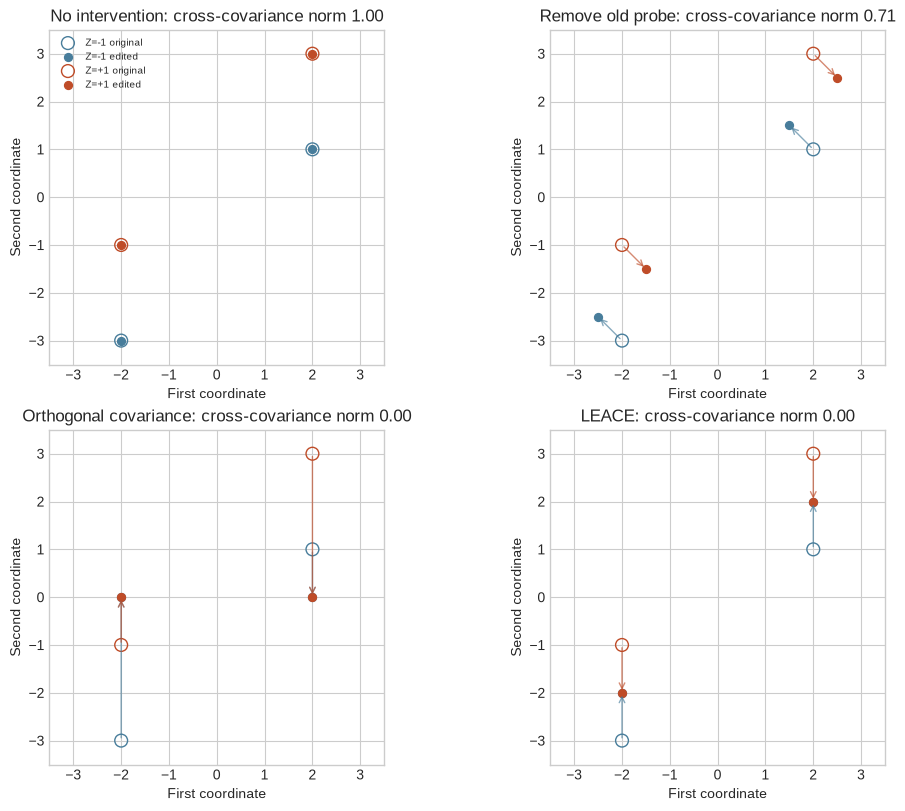

In [8]:
exact_erasers = {
    "No intervention": dict(mean=points.mean(0), left=t.empty(2, 0, dtype=t.float64), right=t.empty(0, 2, dtype=t.float64), rank=0),
    "Remove old probe": old_probe_erasure,
    "Orthogonal covariance": fit_orthogonal_eraser(points, concept_column),
    "LEACE": fit_leace(points, concept_column),
}
exact_edits = {name: apply_eraser(points, fit) for name, fit in exact_erasers.items()}
fig, axes = plt.subplots(2, 2, figsize=(10, 8), constrained_layout=True)
for ax, (name, edited) in zip(axes.flat, exact_edits.items()):
    for label, color in [(0, "#487d9b"), (1, "#bf4c28")]:
        mask = labels == label
        ax.scatter(points[mask, 0], points[mask, 1], facecolors="none", edgecolors=color, s=85, label=f"Z={2*label-1:+d} original")
        ax.scatter(edited[mask, 0], edited[mask, 1], color=color, s=32, label=f"Z={2*label-1:+d} edited")
        for start, end in zip(points[mask], edited[mask]):
            ax.annotate("", xy=end.numpy(), xytext=start.numpy(), arrowprops=dict(arrowstyle="->", color=color, alpha=.65))
    covariance = centered_statistics(edited, concept_column)["cross_covariance"].norm()
    ax.set(title=f"{name}: cross-covariance norm {covariance:.2f}", xlim=(-3.5, 3.5), ylim=(-3.5, 3.5), xlabel="First coordinate", ylabel="Second coordinate", aspect="equal")
axes[0, 0].legend(fontsize=7)
fig.savefig(assets_dir / "erasure_four_point_geometry.png", dpi=160)
plt.show()


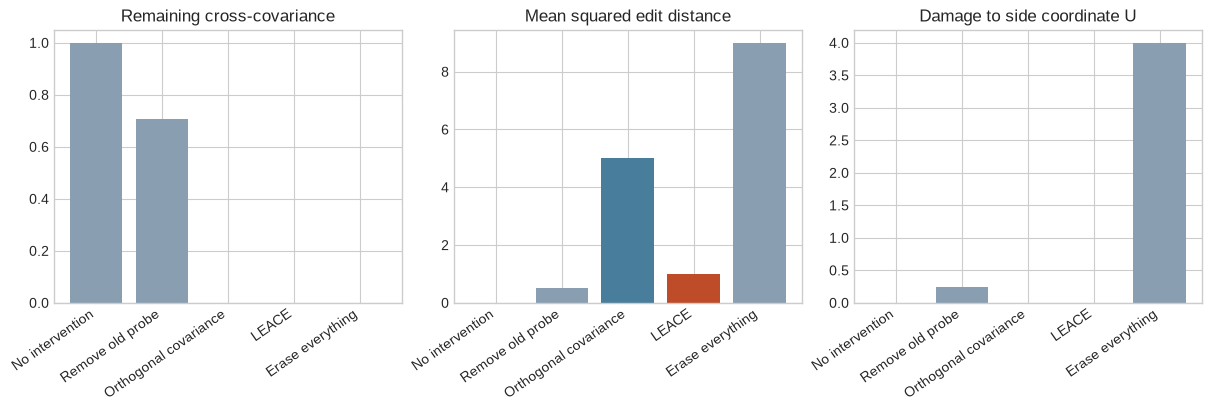

In [9]:
comparison_edits = {**exact_edits, "Erase everything": points.mean(0).expand_as(points)}
fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
for ax, values, title in [
    (axes[0], [float(centered_statistics(x, concept_column)["cross_covariance"].norm()) for x in comparison_edits.values()], "Remaining cross-covariance"),
    (axes[1], [float((x - points).square().sum(1).mean()) for x in comparison_edits.values()], "Mean squared edit distance"),
    (axes[2], [float((x[:, 0] - u).square().mean()) for x in comparison_edits.values()], "Damage to side coordinate U"),
]:
    ax.bar(range(len(values)), values, color=["#8a9eb2", "#8a9eb2", "#487d9b", "#bf4c28", "#8a9eb2"])
    ax.set_xticks(range(len(values)), list(comparison_edits), rotation=35, ha="right")
    ax.set(title=title)
fig.savefig(assets_dir / "erasure_constraint_and_distortion.png", dpi=160)
plt.show()


<details>
<summary>Interpretation — why is the oblique projection smaller?</summary>

Orthogonal projection minimizes distance to a *fixed destination subspace*.
Our constraint does not fix that subspace: it requires the class-mean difference
to lie in the removed map's nullspace. The first coordinate predicts part of
the second, so retaining that prediction gives a different destination with
less average distortion. Removing everything also satisfies the constraint,
but destroys the side variable. A successful constraint alone is insufficient.

</details>


In [10]:
from chapter11_representation_geometry.exercises.part4_concept_erasure.reference_parity import compare_reference
reference_comparison = compare_reference(SimpleNamespace(**globals()))
(assets_dir / "author_parity.json").write_text(json.dumps(reference_comparison, indent=2) + "\n")


Pinned author parity passed for full-rank, singular and translated data.


1193

The comparison loads hash-checked author code from a pinned commit and checks
full-rank, singular and translated examples. It explicitly disables the author
package's covariance shrinkage and trace regularization, so it compares the
same empirical objective. Library defaults are not interchangeable scientific
settings. The separate KKT test gives an oracle that does not reuse whitening.


# 3️⃣ Try to read the concept again

## A new probe gets a new direction

Do not evaluate an eraser solely by applying a probe trained on the original
activations. Its input distribution has changed. Fit a fresh predictor and keep
its intercept: erasure does not make an imbalanced class prior disappear.

For these small balanced examples, constant prediction has log loss `log(2)`.
The following probe standardizes using its training rows only, then minimizes a
convex binary logistic objective with a small, explicit L2 penalty. It returns
the coefficient in the original coordinate system. Its thresholded accuracy
and log loss are separate measurements.


### Exercise 6 — Refit and evaluate a logistic probe

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend 15–20 minutes on this exercise.
> ```

Implement the training-only standardization, scalar intercept and stable logistic objective. Only the probe coefficient and intercept belong in LBFGS. Return a coefficient and intercept usable directly on unstandardized new rows, plus the fitting history. Evaluation must report both log loss and the fraction of correct thresholded predictions.

<details>
<summary>Help</summary>

If the standardized predictor is `(x-mean)/scale @ w + b`, the original-coordinate coefficient is `w/scale` and its intercept is `b - mean @ (w/scale)`. An empty or single-class training task cannot support the intended comparison.

</details>

<details>
<summary>Expected output</summary>

The old probe has loss `log(2)` after its direction is removed, but a new probe improves that loss. After the exact LEACE edit, the constant logistic predictor is optimal on these four points.

</details>

<details>
<summary>Solution</summary>

```python
def fit_binary_probe(x: t.Tensor, labels: t.Tensor, *, l2: float = 1e-3,
                     steps: int = 150) -> dict:
    """Refit a convex logistic probe from training rows only, including an intercept."""
    if x.ndim != 2 or labels.shape != (len(x),) or len(x) < 2:
        raise ValueError("Use one binary label for each representation row.")
    if not t.all((labels == 0) | (labels == 1)) or labels.unique().numel() != 2:
        raise ValueError("Training must contain both binary classes.")
    if not x.is_floating_point() or not t.isfinite(x).all() or l2 < 0 or steps < 1:
        raise ValueError("Use finite floating activations and a valid optimization budget.")
    mean = x.mean(0)
    scale = (x - mean).square().mean(0).sqrt()
    scale = t.where(scale > t.finfo(x.dtype).eps, scale, 1)
    standardized = (x - mean) / scale
    target = labels.to(dtype=x.dtype, device=x.device)
    w = t.zeros(x.shape[1], dtype=x.dtype, device=x.device, requires_grad=True)
    b = target.mean().logit().detach().requires_grad_(True)
    optimizer = t.optim.LBFGS([w, b], max_iter=steps, tolerance_grad=1e-10,
                             tolerance_change=1e-12, line_search_fn="strong_wolfe")
    history = []

    def closure():
        optimizer.zero_grad()
        loss = F.binary_cross_entropy_with_logits(standardized @ w + b, target)
        objective = loss + l2 * w.square().sum() / 2
        objective.backward()
        history.append(float(objective.detach()))
        return objective

    optimizer.step(closure)
    coefficient = w.detach() / scale
    intercept = b.detach() - mean @ coefficient
    return dict(coefficient=coefficient, intercept=intercept, training_mean=mean,
                training_scale=scale, objective_history=history, l2=l2)

def evaluate_binary_probe(x: t.Tensor, labels: t.Tensor, probe: dict) -> dict:
    """Keep convex log loss and thresholded accuracy as different measurements."""
    logits = x @ probe["coefficient"] + probe["intercept"]
    loss = F.binary_cross_entropy_with_logits(logits, labels.to(logits))
    return dict(log_loss=float(loss), accuracy=float(((logits > 0) == labels.bool()).double().mean()),
                probabilities=logits.sigmoid(), logits=logits)
```

</details>


In [ ]:
def fit_binary_probe(x: t.Tensor, labels: t.Tensor, *, l2: float=0.001, steps: int=150) -> dict:
    """Refit a convex logistic probe from training rows only, including an intercept."""
    raise NotImplementedError()

def evaluate_binary_probe(x: t.Tensor, labels: t.Tensor, probe: dict) -> dict:
    """Keep convex log loss and thresholded accuracy as different measurements."""
    raise NotImplementedError()

tests.test_probe_removal_requires_refitting(SimpleNamespace(**globals()))
tests.test_nonlinear_information_and_loss_boundary(SimpleNamespace(**globals()))


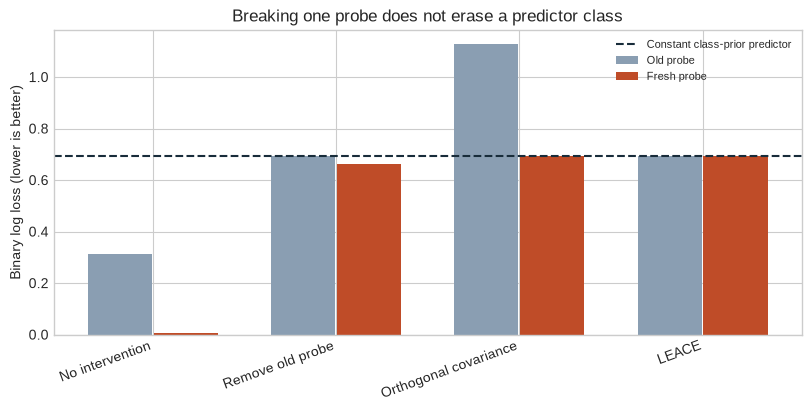

In [12]:
old_probe = dict(coefficient=t.tensor([-1., 1.], dtype=t.float64), intercept=t.tensor(0., dtype=t.float64))
probe_results = {}
for name, edited in exact_edits.items():
    fresh_probe = fit_binary_probe(edited, labels, l2=1e-4)
    probe_results[name] = dict(old=evaluate_binary_probe(edited, labels, old_probe), fresh=evaluate_binary_probe(edited, labels, fresh_probe))
fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
for offset, field, color in [(-.18, "old", "#8a9eb2"), (.18, "fresh", "#bf4c28")]:
    ax.bar(np.arange(len(probe_results)) + offset, [row[field]["log_loss"] for row in probe_results.values()], width=.35, label=f"{field.capitalize()} probe", color=color)
ax.axhline(math.log(2), color="#182c3a", linestyle="--", label="Constant class-prior predictor")
ax.set_xticks(range(len(probe_results)), list(probe_results), rotation=20, ha="right")
ax.set(ylabel="Binary log loss (lower is better)", title="Breaking one probe does not erase a predictor class")
ax.legend(fontsize=8)
fig.savefig(assets_dir / "erasure_probe_refitting.png", dpi=160)
plt.show()


## A guarantee can hold while information survives

Consider representations at `-2, +2` for class 1 and `-1, +1` for class 0.
Both class means are zero. LEACE correctly makes no edit. Squaring the
representation still reveals the class perfectly.

There is a subtler point: the hard threshold `x > 1.5` is correct on three of
four examples. Its log loss is worse than constant prediction. The theorem
concerns losses convex in affine logits; 0–1 classification loss is not one of
them. Inspect both panels before deciding what “chance performance” means.


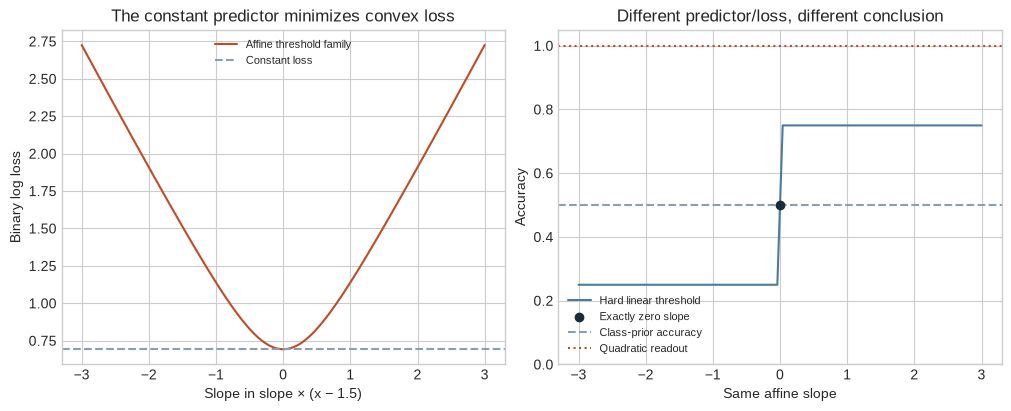

In [13]:
nonlinear_x = t.tensor([[-2.], [2.], [-1.], [1.]], dtype=t.float64)
nonlinear_labels = t.tensor([1, 1, 0, 0])
nonlinear_z = F.one_hot(nonlinear_labels, 2).double()
nonlinear_edit = apply_eraser(nonlinear_x, fit_leace(nonlinear_x, nonlinear_z))
slopes = t.linspace(-3, 3, 151, dtype=t.float64)
slopes[75] = 0.  # Make the constant predictor exact rather than a rounding-sized slope.
logits = slopes[:, None] * (nonlinear_edit[:, 0] - 1.5)[None]
losses = F.binary_cross_entropy_with_logits(logits, nonlinear_labels.double().expand_as(logits), reduction="none").mean(1)
accuracies = ((logits > 0) == nonlinear_labels.bool()).double().mean(1)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
axes[0].plot(slopes, losses, label="Affine threshold family", color="#bf4c28")
axes[0].axhline(math.log(2), color="#8a9eb2", linestyle="--", label="Constant loss")
axes[0].set(xlabel="Slope in slope × (x − 1.5)", ylabel="Binary log loss", title="The constant predictor minimizes convex loss")
axes[0].legend(fontsize=8)
axes[1].plot(slopes, accuracies, color="#487d9b", label="Hard linear threshold")
axes[1].scatter([0], [.5], color="#182c3a", zorder=3, label="Exactly zero slope")
axes[1].axhline(.5, color="#8a9eb2", linestyle="--", label="Class-prior accuracy")
axes[1].axhline(float(((nonlinear_edit[:, 0].square() > 2.5) == nonlinear_labels.bool()).double().mean()), color="#bf4c28", linestyle=":", label="Quadratic readout")
axes[1].set(xlabel="Same affine slope", ylabel="Accuracy", ylim=(0, 1.05), title="Different predictor/loss, different conclusion")
axes[1].legend(fontsize=8)
fig.savefig(assets_dir / "erasure_nonlinear_counterexample.png", dpi=160)
plt.show()


## Try It Yourself — change the predictable side contribution

Change `SIDE_SCALE` and `COUPLING`. Predict how the orthogonal baseline's
collateral distortion changes before rerunning. The complete pairing of each
side value with both concepts keeps the two latent variables independent in
this finite dataset. This play alters the mechanism, not only the plot limits.
Afterwards, add an independent constant third coordinate and verify that the
affine eraser preserves it without trying to invert its zero variance.


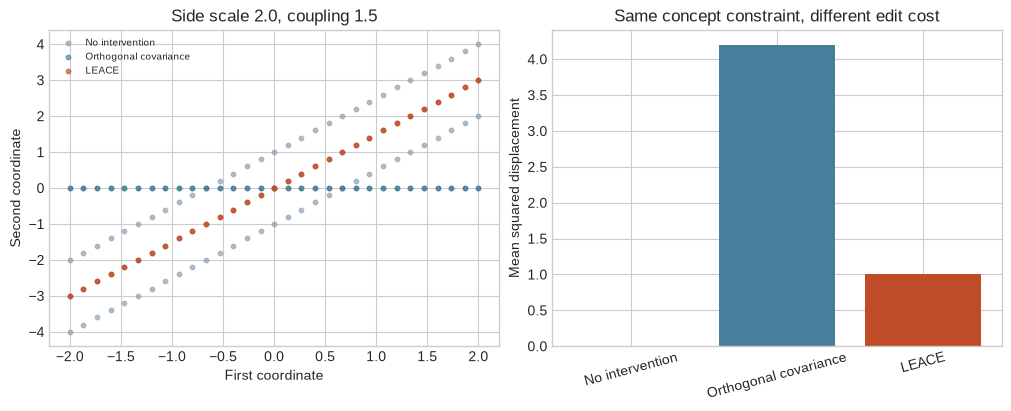

In [14]:
SIDE_SCALE, COUPLING = 2., 1.5
side_grid = t.linspace(-SIDE_SCALE, SIDE_SCALE, 31, dtype=t.float64).repeat_interleave(2)
play_concept = t.tensor([-1., 1.], dtype=t.float64).repeat(31)
play_x = t.stack((side_grid, COUPLING * side_grid + play_concept), 1)
play_edits = {
    "No intervention": play_x,
    "Orthogonal covariance": apply_eraser(play_x, fit_orthogonal_eraser(play_x, play_concept[:, None])),
    "LEACE": apply_eraser(play_x, fit_leace(play_x, play_concept[:, None])),
}
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for (name, edited), color in zip(play_edits.items(), ["#8a9eb2", "#487d9b", "#bf4c28"]):
    axes[0].scatter(edited[:, 0], edited[:, 1], s=10, alpha=.65, label=name, color=color)
axes[0].set(xlabel="First coordinate", ylabel="Second coordinate", title=f"Side scale {SIDE_SCALE}, coupling {COUPLING}")
axes[0].legend(fontsize=7)
axes[1].bar(list(play_edits), [float((x - play_x).square().sum(1).mean()) for x in play_edits.values()], color=["#8a9eb2", "#487d9b", "#bf4c28"])
axes[1].set(ylabel="Mean squared displacement", title="Same concept constraint, different edit cost")
axes[1].tick_params(axis="x", rotation=15)
fig.savefig(assets_dir / "erasure_covariance_play.png", dpi=160)
plt.show()


<!-- Native study starts here -->
# 4️⃣ What happens inside GPT-2?

## A role, a readout, and an answer

Consider `At the station, Mary met John, and Mary handed a ticket to`.
The expected next name is John. Our binary concept $R$ says whether the repeated
subject is the first or the second person. Removing a representation of $R$
might impair the model's answer, leave it unchanged, or damage unrelated
information as well. A probe alone cannot distinguish these outcomes.

We intervene at two prescribed sites: the input to block 6 at the repeated
subject token, and the input to block 9 at the last token. Block numbers are
zero-based. Only one residual vector is edited per sentence; all later native
transformer blocks, normalization and the full vocabulary head still execute.
The helper below handles tokenization, padding, hooks and cached continuation.
The eraser and every comparison are built with the functions you implemented.

We also ask the model to recall an object: `Mary and John found a book. Then
Mary picked up the book. They found a`. The correct object does not depend on
$R$. This provides a concrete collateral-damage measurement. These object
sentences differ from the role-fitting distribution, so success there would
be a useful observation rather than a theorem about preserved information.

## Keep four roles for the data

| Split | Role prompts | Purpose |
| --- | ---: | --- |
| Eraser fitting | 512 | Fit moments and the original probe |
| Independent probe fitting | 320 | Fit a new reader on transformed inputs |
| Development | 160 | Inspect the prescribed comparison |
| Final | 288 | Evaluate all retained conditions on new frames and name pairs |

There are also 320 development and 384 final object prompts. We keep native
errors and every declared example. Both roles are balanced. The second split
matters: fitting a probe only on the very examples whose cross-covariance was
forced to zero can hide information that remains recoverable on new inputs.

The fixed model is GPT-2 revision `607a30d783dfa663caf39e06633721c8d4cfcd7e`.
The CPU experiment uses float32 native activations and float64 moment/probe
fitting. It requires the repository environment, about 16 GB of free RAM and
about 16 GB of disk if you retain every full-vocabulary result. Allow several
minutes for execution after solving the exercises. This cell uses the local
checkpoint; if absent, download it once from the repository root:

```bash
uv run hf download gpt2 --revision 607a30d783dfa663caf39e06633721c8d4cfcd7e
```

You can stop after the exact examples and return to this part later. The native
experiment is an explicit second stage, with its own visible results.


In [15]:
from transformers import AutoModelForCausalLM, AutoTokenizer
from chapter11_representation_geometry.exercises.part4_concept_erasure import erasure_data as data
from chapter11_representation_geometry.exercises.part4_concept_erasure import erasure_protocol as protocol
from chapter11_representation_geometry.exercises.part4_concept_erasure.erasure_native import (
    capture_native, continue_native, full_forward_intervention, weight_digest,
)
import hashlib

# This helper only writes readable metrics. Tensor evidence is saved separately.
def plain_metrics(value):
    if isinstance(value, t.Tensor):
        return value.tolist()
    if isinstance(value, dict):
        return {key: plain_metrics(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [plain_metrics(item) for item in value]
    return value


def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


tokenizer = AutoTokenizer.from_pretrained(data.MODEL_ID, revision=data.REVISION, local_files_only=True)
tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "left"
model = AutoModelForCausalLM.from_pretrained(
    data.MODEL_ID, revision=data.REVISION, local_files_only=True,
    dtype=t.float32, attn_implementation="eager",
).cpu().eval()
model.requires_grad_(False)
weights_before = weight_digest(model)
rows = {split: data.prompt_rows(split) for split in ["train", "probe_train", "development"]}
rows["object_development"] = data.prompt_rows("development", "object")
answer_ids = data.answer_token_ids(tokenizer, rows["train"])
caches = {split: capture_native(model, tokenizer, values, layers=(6, 9)) for split, values in rows.items()}
role_labels = {split: t.tensor([row["role"] for row in rows[split]]) for split in ["train", "probe_train", "development"]}
print("All 512 eraser-fitting, 320 probe-fitting, 160 development and 320 object rows captured.")
print("Example:", rows["development"][0]["prompt"], "→", rows["development"][0]["answer"])


W0906 16:30:08.653000 2376664 .venv/lib/python3.14/site-packages/torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W0906 16:30:08.664000 2376664 .venv/lib/python3.14/site-packages/torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

All 512 eraser-fitting, 320 probe-fitting, 160 development and 320 object rows captured.
Example: During lunch, Mary spoke with Tom, and Mary handed a letter to → Tom


## Match the intervention, then compare the behavior

A rank-one oblique edit can move an activation much further than a rank-one
orthogonal projection. A random rank-one baseline therefore controls the
number of removed directions but not the amount of damage. We will show both
rank-matched and displacement-matched controls.

For each fixed random unit vector $q$, let $d_i$ be the length of the LEACE
edit for example $i$. Our matched control is

$$x'_i=x_i-\operatorname{sign}((x_i-\mu)^Tq)\,d_iq.$$

Use positive sign when the projection is exactly zero. This control receives
no evaluation label. It has the same displacement length on **each example**,
not just on average. Because its magnitude depends on the input, it is a
nonlinear control; it is not an affine eraser or a competing LEACE solution.


### Exercise 7 — Match each random edit to its target magnitude

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend 10–15 minutes on this exercise.
> ```

Implement the equation above using `apply_eraser` to obtain the target
magnitude. The tests check per-example lengths, direction, zero edit, and that
the control does not accidentally reuse the learned direction.

Expected output: `Per-example norm, random direction and zero-edit control checks passed!`

<details>
<summary>Help</summary>

Compute one norm per row with `norm(dim=-1)`. Do not normalize all examples
by one global norm. The sign orients the random edit toward the fitted mean
along $q$; its length still comes from the target eraser.

</details>

<details>
<summary>Solution</summary>

```python
def matched_random_edit(x: t.Tensor, mean: t.Tensor, direction: t.Tensor,
                        target_eraser: dict) -> t.Tensor:
    """A control with each example's target edit norm and a fixed random direction.

    This magnitude-matched control is nonlinear in X. It is not claimed to be
    an affine eraser or to satisfy a zero-cross-covariance constraint.
    """
    if direction.shape != (x.shape[1],) or mean.shape != direction.shape:
        raise ValueError("Use one random direction and the training mean.")
    if not t.allclose(direction.norm(), direction.new_tensor(1.), atol=1e-10, rtol=1e-10):
        raise ValueError("The random direction must have unit length.")
    magnitude = (apply_eraser(x, target_eraser) - x).norm(dim=-1)
    projection = (x - mean) @ direction
    sign = t.where(projection >= 0, 1., -1.)
    return x - (sign * magnitude)[:, None] * direction
```

</details>


In [ ]:
def matched_random_edit(x: t.Tensor, mean: t.Tensor, direction: t.Tensor, target_eraser: dict) -> t.Tensor:
    """A control with each example's target edit norm and a fixed random direction.

This magnitude-matched control is nonlinear in X. It is not claimed to be
an affine eraser or to satisfy a zero-cross-covariance constraint."""
    raise NotImplementedError()

tests.test_random_control_matches_each_edit_norm(SimpleNamespace(**globals()))


### Exercise 8 — Measure answers and collateral changes separately

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend 10–15 minutes on this exercise.
> ```

Given intervened logits, original logits and target token IDs, return the
number correct, accuracy, target log loss/probability, native-correct count and
how many of those answers were preserved. Also compute $D_{KL}(q\|p)$ from the
native distribution $q$ to the intervened distribution $p$, and the fraction
of changed winning tokens. Normalize over the full vocabulary.

Expected output: `Actual target, native-error denominator and full-vocabulary KL checks passed!`

<details>
<summary>Help</summary>

Use `log_softmax` for both distributions. A changed winner can be a repair
of an original mistake; keep native accuracy separate from intervention
accuracy. Restricting normalization to the two names would conceal other
answers, so the test includes a third token.

</details>

<details>
<summary>Solution</summary>

```python
def compare_model_outputs(logits: t.Tensor, native_logits: t.Tensor, targets: t.Tensor) -> dict:
    """Separate answer correctness, confidence, distribution change and native errors."""
    if (logits.ndim != 2 or logits.shape != native_logits.shape or not len(logits)
            or targets.shape != (len(logits),)):
        raise ValueError("Use two equally shaped full-vocabulary batches and one target per row.")
    if not t.isfinite(logits).all() or not t.isfinite(native_logits).all():
        raise ValueError("Native comparisons require finite logits.")
    log_p, log_q = logits.log_softmax(-1), native_logits.log_softmax(-1)
    correct, native_correct = logits.argmax(-1) == targets, native_logits.argmax(-1) == targets
    return dict(rows=len(logits), accuracy=float(correct.double().mean()), correct=int(correct.sum()),
                native_correct_count=int(native_correct.sum()),
                preserved_native_correct=int((correct & native_correct).sum()),
                answer_loss=float(F.cross_entropy(logits, targets)),
                answer_probability=float(log_p[t.arange(len(logits)), targets].exp().mean()),
                kl_from_native=float((log_q.exp() * (log_q - log_p)).sum(-1).mean()),
                changed_winner_fraction=float((logits.argmax(-1) != native_logits.argmax(-1)).double().mean()))
```

</details>


In [ ]:
def compare_model_outputs(logits: t.Tensor, native_logits: t.Tensor, targets: t.Tensor) -> dict:
    """Separate answer correctness, confidence, distribution change and native errors."""
    raise NotImplementedError()

tests.test_actual_vocabulary_outcome_metrics(SimpleNamespace(**globals()))


## Fit the erasers before opening the final set

The empirical covariance has dimension 768 but only 512 fitting rows; its rank
cannot exceed 511. The exact eraser is defined on that empirical support.
For new examples, very small fitted variances can amplify an edit. We keep both
the empirical solution and a fixed 0.01 spherical covariance mixture. The
mixture changes the distortion objective: it must not be described as the
exact minimum of the original empirical objective.

The code retains all five prescribed methods at both sites. It also keeps all
16 random directions at each site, and matches each direction to both LEACE
variants. No method, site or random draw is selected using final outcomes.
The newly fitted reader uses only the independent probe-fitting split, including
its standardization. All choices are in `erasure_protocol.py` and can be read
alongside this cell.

<details>
<summary>Why keep the original probe?</summary>

It is useful as a negative example: projecting away its coefficient can disable
that reader while leaving another reader effective. It is not our only erasure
measurement. Every edited representation receives a new independently fitted
reader before final evaluation.

</details>


In [18]:
# A condition stores either an affine eraser or a magnitude-matched control.
# These transformations remain visible and editable in the notebook.
def edit_condition(x, condition):
    if condition["family"].startswith("Matched"):
        return matched_random_edit(x, condition["eraser"]["mean"], condition["direction"], condition["eraser"])
    return apply_eraser(x, condition["eraser"])


def probe_scalars(result):
    return {key: result[key] for key in ["log_loss", "accuracy"]}


condition_bank = {}
training_results = []
for site_index, (layer, position) in enumerate(protocol.SITES):
    site = f"{layer}/{position}"
    train_x = caches["train"].activations(layer, position).double()
    probe_x = caches["probe_train"].activations(layer, position).double()
    z = F.one_hot(role_labels["train"], 2).double()
    old_reader = fit_binary_probe(train_x, role_labels["train"], l2=protocol.PROBE_L2, steps=protocol.PROBE_STEPS)
    q = old_reader["coefficient"] / old_reader["coefficient"].norm()
    mean, width = train_x.mean(0), train_x.shape[1]
    erasers = {
        "No intervention": dict(mean=mean, left=train_x.new_empty(width, 0), right=train_x.new_empty(0, width), rank=0),
        "Probe coefficient": dict(mean=mean, left=q[:, None], right=q[None], rank=1),
        "Orthogonal covariance": fit_orthogonal_eraser(train_x, z, svd_atol=protocol.SVD_ATOL),
        "LEACE empirical": fit_leace(train_x, z, svd_atol=protocol.SVD_ATOL),
        "LEACE shrinkage .01": fit_leace(train_x, z, svd_atol=protocol.SVD_ATOL, shrinkage=protocol.SHRINKAGE),
    }
    conditions = {name: dict(family=name, eraser=eraser) for name, eraser in erasers.items()}
    for draw in range(protocol.RANDOM_DRAWS):
        seed = protocol.RANDOM_SEED_STARTS[site_index] + draw
        random_q = t.randn(width, generator=t.Generator().manual_seed(seed), dtype=t.float64)
        random_q = random_q / random_q.norm()
        random_eraser = dict(mean=mean, left=random_q[:, None], right=random_q[None], rank=1)
        conditions[f"Random rank one/draw{draw:02d}"] = dict(family="Random rank one", eraser=random_eraser, seed=seed)
        for family, target in [("Matched empirical", "LEACE empirical"), ("Matched shrinkage", "LEACE shrinkage .01")]:
            conditions[f"{family}/draw{draw:02d}"] = dict(family=family, eraser=erasers[target], direction=random_q, seed=seed)
    assert set(conditions) == set(protocol.condition_names())
    for name in protocol.condition_names():
        condition = conditions[name]
        edited_train = edit_condition(train_x, condition)
        edited_probe_train = edit_condition(probe_x, condition)
        condition["old_reader"] = old_reader
        condition["new_reader"] = fit_binary_probe(edited_probe_train, role_labels["probe_train"], l2=protocol.PROBE_L2, steps=protocol.PROBE_STEPS)
        fit_metrics = dict(
            site=site, method=name, family=condition["family"],
            covariance_norm=float(centered_statistics(edited_train, z)["cross_covariance"].norm()),
            mse=float((edited_train - train_x).square().sum(1).mean()),
            covariance_rank=condition["eraser"].get("covariance_rank"),
        )
        if name in erasers:
            fitting_reader = fit_binary_probe(edited_train, role_labels["train"], l2=protocol.PROBE_L2, steps=protocol.PROBE_STEPS)
            condition["fitting_reader"] = fitting_reader
            fit_metrics["fitting_probe"] = probe_scalars(evaluate_binary_probe(edited_train, role_labels["train"], fitting_reader))
        training_results.append(fit_metrics)
    condition_bank[site] = conditions
    print(f"{site}: all {len(conditions)} conditions fitted; empirical covariance rank {erasers['LEACE empirical']['covariance_rank']} / {width}.")

# Save all fitted parameters before constructing the final model inputs.
t.save(condition_bank, assets_dir / "fitted_conditions.pt")
fitted_conditions_sha256 = file_sha256(assets_dir / "fitted_conditions.pt")


6/subject: all 53 conditions fitted; empirical covariance rank 511 / 768.


9/end: all 53 conditions fitted; empirical covariance rank 511 / 768.


## Check the development result

The expected distinction is between an exact fitting constraint and a new-data
measurement. The empirical and covariance-mixture erasers should drive fitting
cross-covariance close to zero. A refitted logistic probe on those same fitting
examples should then have log loss near $\log 2$. Neither statement predicts
the loss of a reader fitted on the separate probe-training sentences.

Use the next plot to inspect that distinction. A new-data loss above $\log 2$
is a poorly calibrated or wrong reader, not evidence of “more than complete”
erasure. Accuracy and convex loss answer different questions.


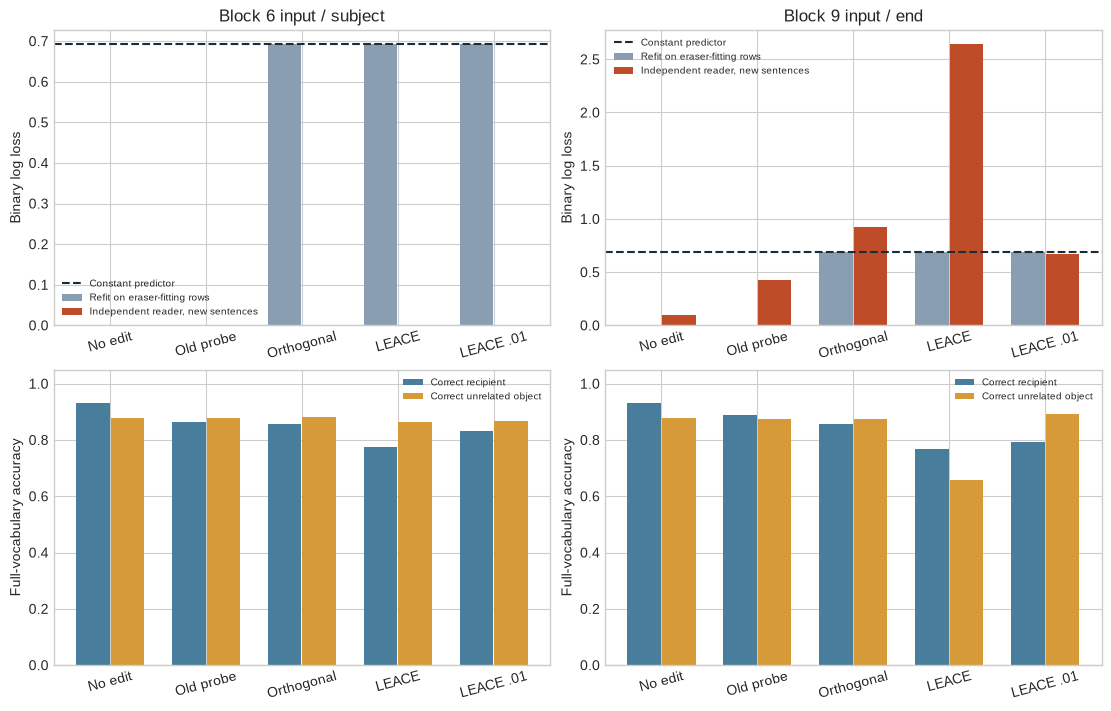

In [19]:
@t.no_grad()
def run_native_condition(cache, layer, position, condition, batch_size=24):
    activations = cache.activations(layer, position).double()
    outputs, replacements = [], []
    for start in range(0, len(activations), batch_size):
        indices = t.arange(start, min(start + batch_size, len(activations)))
        replacement = edit_condition(activations[indices], condition).to(cache.logits.dtype)
        outputs.append(continue_native(model, cache, layer, indices, replacement, position))
        replacements.append(replacement)
    return t.cat(outputs), t.cat(replacements)


base_names = protocol.condition_names()[:5]
development_results = []
for layer, position in protocol.SITES:
    site = f"{layer}/{position}"
    for name in base_names:
        condition = condition_bank[site][name]
        edited = edit_condition(caches["development"].activations(layer, position).double(), condition)
        result = dict(site=site, method=name,
                      new_probe=probe_scalars(evaluate_binary_probe(edited, role_labels["development"], condition["new_reader"])))
        for task in ["development", "object_development"]:
            logits, replacements = run_native_condition(caches[task], layer, position, condition)
            targets = t.tensor([answer_ids[row["answer"]] for row in rows[task]])
            result[task] = compare_model_outputs(logits, caches[task].logits, targets)
            with t.no_grad():
                independent_logits = full_forward_intervention(model, caches[task], layer, t.arange(8), replacements[:8], position)
            t.testing.assert_close(logits[:8], independent_logits, atol=3e-4, rtol=0)
        development_results.append(result)

short_names = ["No edit", "Old probe", "Orthogonal", "LEACE", "LEACE .01"]
colors = ["#8a9eb2", "#9d73a8", "#487d9b", "#bf4c28", "#d69a39"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
for column, (layer, position) in enumerate(protocol.SITES):
    site = f"{layer}/{position}"
    fitted = [next(row for row in training_results if row["site"] == site and row["method"] == name) for name in base_names]
    developed = [row for row in development_results if row["site"] == site]
    x_axis = np.arange(5)
    axes[0, column].bar(x_axis - .18, [row["fitting_probe"]["log_loss"] for row in fitted], width=.35, color="#8a9eb2", label="Refit on eraser-fitting rows")
    axes[0, column].bar(x_axis + .18, [row["new_probe"]["log_loss"] for row in developed], width=.35, color="#bf4c28", label="Independent reader, new sentences")
    axes[0, column].axhline(math.log(2), color="#182c3a", linestyle="--", label="Constant predictor")
    axes[0, column].set(title=f"Block {layer} input / {position}", ylabel="Binary log loss")
    axes[0, column].legend(fontsize=7)
    axes[1, column].bar(x_axis - .18, [row["development"]["accuracy"] for row in developed], width=.35, color="#487d9b", label="Correct recipient")
    axes[1, column].bar(x_axis + .18, [row["object_development"]["accuracy"] for row in developed], width=.35, color="#d69a39", label="Correct unrelated object")
    axes[1, column].set(ylabel="Full-vocabulary accuracy", ylim=(0, 1.05))
    axes[1, column].legend(fontsize=7)
    for ax in axes[:, column]:
        ax.set_xticks(x_axis, short_names, rotation=15)
fig.savefig(assets_dir / "erasure_native_development.png", dpi=160)
plt.show()


<details>
<summary>Help — interpret the development comparison</summary>

The training-distribution guarantee and new-sentence behavior can diverge sharply.
At the repeated subject, a reader trained on separate erased sentences can still
recover the role, even after the empirical fitting covariance is zero. At the
later site, an empirical eraser can produce much larger new-input displacements
and reduce object accuracy as well as recipient accuracy. The .01 mixture
changes that behavior; it does not turn the finite training theorem into a
generalization guarantee.

Compare the actual values from your execution. If you change training data or
numerics, do not assume the original pattern will survive. The full-forward
checks above verify that a cached continuation agrees with an independent hook
on the complete model. They do not certify that the edited direction uniquely
represents the intended concept.

</details>

## Final evaluation: every retained condition

The next cell is the first final evaluation. All fitted maps and probes already
exist. It evaluates both sites, all 16 draws of each control family, all 288 role
sentences and all 384 object sentences. The control families appear as spreads
of actual draws in the figures; their variation is not a confidence interval over
people, natural language or all possible seeds.

We save one tensor file per condition so the complete vocabulary predictions
remain inspectable without keeping every condition in RAM. The plots below
are generated from these executed interventions and actual token outputs.
Rerunning the analysis after seeing these results is exploratory work on an
already inspected final set.


In [20]:
assert file_sha256(assets_dir / "fitted_conditions.pt") == fitted_conditions_sha256
rows["final"] = data.prompt_rows("final")
rows["object_final"] = data.prompt_rows("final", "object")
assert len(rows["final"]) == protocol.FINAL_ROLE_ROWS
assert len(rows["object_final"]) == protocol.FINAL_OBJECT_ROWS
for task in ["final", "object_final"]:
    caches[task] = capture_native(model, tokenizer, rows[task], layers=(6, 9))
role_labels["final"] = t.tensor([row["role"] for row in rows["final"]])
t.save(dict(rows=rows, baseline_logits={key: cache.logits for key, cache in caches.items()},
            activations={f"{layer}/{position}": {split: cache.activations(layer, position) for split, cache in caches.items()}
                         for layer, position in protocol.SITES}), assets_dir / "native_inputs.pt")
condition_dir = assets_dir / "conditions"
condition_dir.mkdir(exist_ok=True)
final_results, tensor_files = [], {}
for site_index, (layer, position) in enumerate(protocol.SITES):
    site = f"{layer}/{position}"
    for method_index, name in enumerate(protocol.condition_names()):
        condition = condition_bank[site][name]
        role_x = caches["final"].activations(layer, position).double()
        edited_role = edit_condition(role_x, condition)
        new_probe_result = evaluate_binary_probe(edited_role, role_labels["final"], condition["new_reader"])
        old_probe_result = evaluate_binary_probe(edited_role, role_labels["final"], condition["old_reader"])
        result = dict(site=site, method=name, family=condition["family"],
                      new_probe=probe_scalars(new_probe_result), old_probe=probe_scalars(old_probe_result),
                      final_covariance_norm=float(centered_statistics(edited_role, F.one_hot(role_labels["final"], 2).double())["cross_covariance"].norm()))
        actual = dict(new_probe=new_probe_result, old_probe=old_probe_result)
        for task in ["final", "object_final"]:
            cache = caches[task]
            logits, replacements = run_native_condition(cache, layer, position, condition)
            targets = t.tensor([answer_ids[row["answer"]] for row in rows[task]])
            result[task] = compare_model_outputs(logits, cache.logits, targets)
            original = cache.activations(layer, position)
            result[task]["mse"] = float((replacements.double() - original.double()).square().sum(1).mean())
            actual[task] = dict(logits=logits, replacements=replacements, targets=targets)
            # One independent full model check per task and retained condition.
            with t.no_grad():
                oracle = full_forward_intervention(model, cache, layer, t.arange(2), replacements[:2], position)
            result[task]["native_hook_max_error"] = float((oracle - logits[:2]).abs().max())
            t.testing.assert_close(logits[:2], oracle, atol=3e-4, rtol=0)
            if name == "No intervention":
                t.testing.assert_close(logits, cache.logits, atol=3e-4, rtol=0)
            if condition["family"].startswith("Matched"):
                original64 = original.double()
                target_norm = (apply_eraser(original64, condition["eraser"]) - original64).norm(dim=1)
                actual_norm = (edit_condition(original64, condition) - original64).norm(dim=1)
                t.testing.assert_close(actual_norm, target_norm, atol=1e-10, rtol=1e-10)
        filename = f"site{site_index}_method{method_index:02d}.pt"
        t.save(actual, condition_dir / filename)
        result["tensor_file"] = f"conditions/{filename}"
        tensor_files[result["tensor_file"]] = file_sha256(condition_dir / filename)
        final_results.append(result)
        if method_index % 10 == 0 or method_index == protocol.CONDITIONS_PER_SITE - 1:
            print(f"{site}: evaluated {method_index + 1}/{protocol.CONDITIONS_PER_SITE} conditions")

assert len(final_results) == 2 * protocol.CONDITIONS_PER_SITE
native_summary = dict(
    status="PASS", model_id=data.MODEL_ID, revision=data.REVISION,
    weights_sha256=weights_before, weights_unchanged=weight_digest(model) == weights_before,
    model_gradients_absent=all(parameter.grad is None for parameter in model.parameters()),
    final_role_rows=len(rows["final"]), final_object_rows=len(rows["object_final"]),
    conditions=len(final_results), final_outcomes=len(final_results) * (len(rows["final"]) + len(rows["object_final"])),
    fitted_conditions_sha256=fitted_conditions_sha256, native_inputs_sha256=file_sha256(assets_dir / "native_inputs.pt"),
    condition_tensor_sha256=tensor_files, training=training_results, development=development_results, final=final_results,
)
assert native_summary["weights_unchanged"] and native_summary["model_gradients_absent"]
(assets_dir / "native_summary.json").write_text(json.dumps(plain_metrics(native_summary), indent=2) + "\n")
print(f"Completed {native_summary['final_outcomes']:,} actual next-token outcomes; model weights unchanged.")


6/subject: evaluated 1/53 conditions


6/subject: evaluated 11/53 conditions


6/subject: evaluated 21/53 conditions


6/subject: evaluated 31/53 conditions


6/subject: evaluated 41/53 conditions


...

9/end: evaluated 31/53 conditions


9/end: evaluated 41/53 conditions


9/end: evaluated 51/53 conditions


9/end: evaluated 53/53 conditions


Completed 71,232 actual next-token outcomes; model weights unchanged.


## Did a new reader recover the role?

Start with probe loss and accuracy on the final sentences. Both use the same
reader, fitted on the separate probe-training split after the intervention.
The dashed constant-predictor baselines are $\log 2$ and $1/2$ because the roles
are balanced. We also show the training and final cross-covariance norms.
Equalizing class means in the fitting sample is directly checkable; equalizing
them in a new sample is a separate observation.

The dots in each control family represent all 16 fixed directions; the short
horizontal mark is their mean. Compare effect size and spread before claiming
the learned transformation is special.

<details>
<summary>Interpreting the final probe comparison</summary>

In the reference execution, the early-site empirical eraser leaves 286/288
roles recoverable by the independent reader (99.3%), with log loss 0.031.
The fitting-set covariance constraint held, but the concept remains readable
on the new sentences. This directly separates an empirical guarantee from
transfer to a new distribution.

At the later site, empirical erasure gives 50% threshold accuracy but log loss
5.205, far worse than the constant predictor's 0.693. Do not call this proof of
information removal: this particular reader is confidently wrong on many
examples, and the final cross-covariance is nonzero. Even the unedited later-site
reader has loss 0.978 despite 81.9% accuracy, so calibration and domain change
already matter before erasure.

</details>


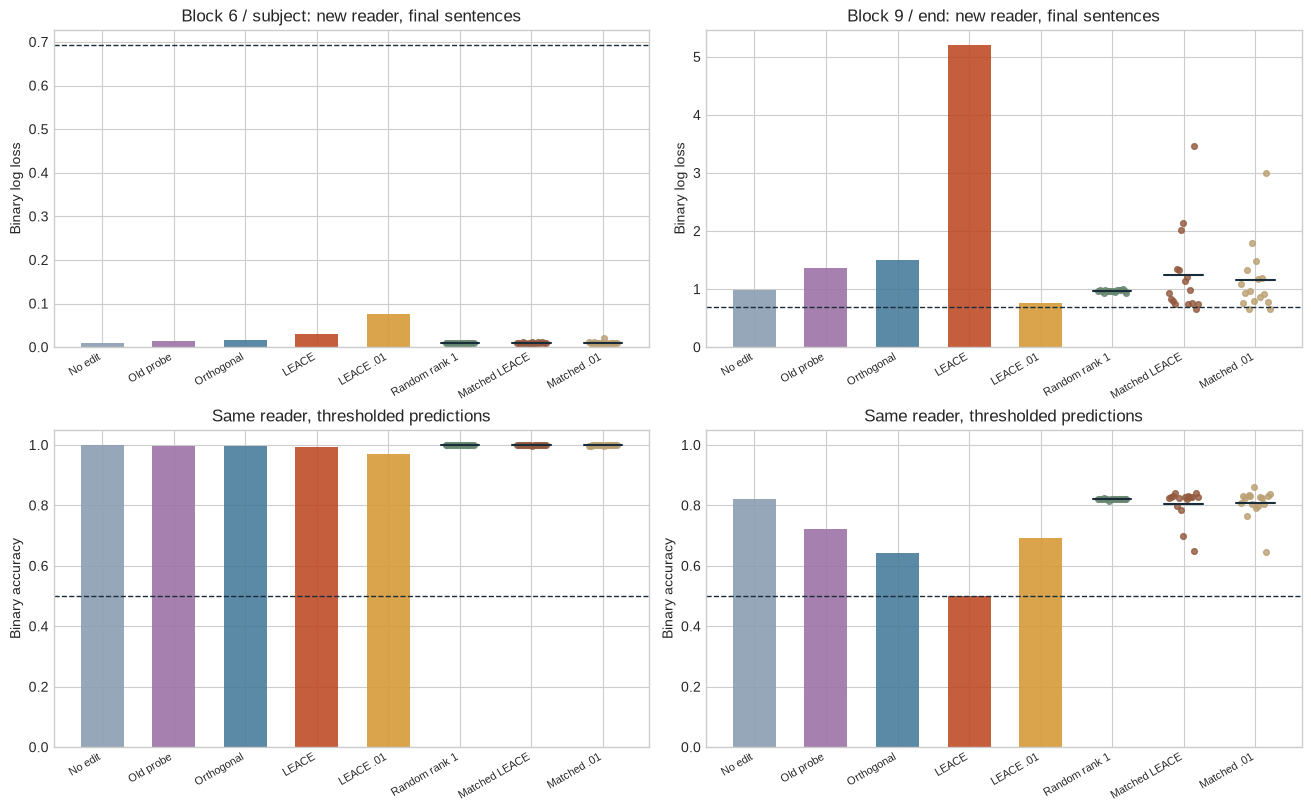

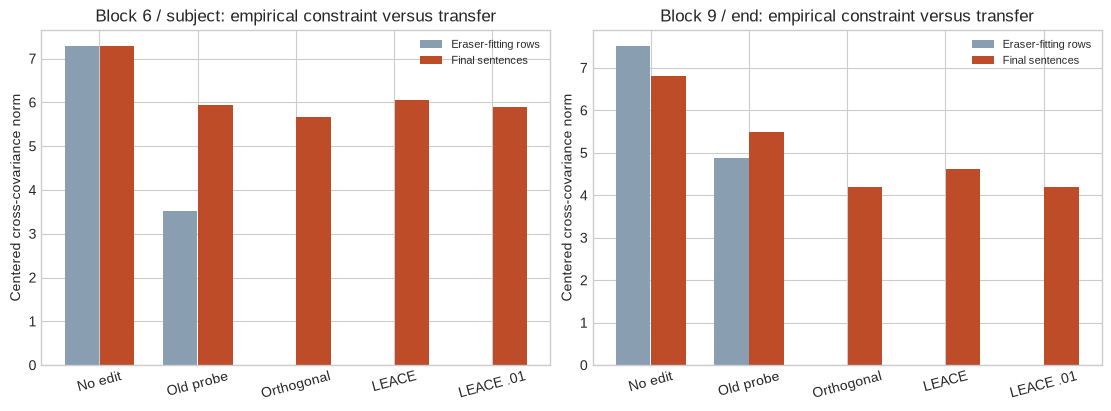

In [21]:
family_order = base_names + ["Random rank one", "Matched empirical", "Matched shrinkage"]
family_labels = short_names + ["Random rank 1", "Matched LEACE", "Matched .01"]
family_colors = colors + ["#678770", "#93593d", "#baa071"]


def plot_condition_values(ax, site, getter, ylabel, title, reference=None):
    for index, (family, color) in enumerate(zip(family_order, family_colors)):
        values = [getter(row) for row in final_results if row["site"] == site and row["family"] == family]
        if len(values) == 1:
            ax.bar(index, values[0], width=.6, color=color, alpha=.9)
        else:
            jitter = np.linspace(-.2, .2, len(values))
            ax.scatter(index + jitter, values, color=color, s=17, alpha=.8)
            ax.plot([index - .27, index + .27], [np.mean(values)] * 2, color="#182c3a", linewidth=1.5)
    if reference is not None:
        ax.axhline(reference, color="#182c3a", linestyle="--", linewidth=1, label="Constant baseline")
    ax.set_xticks(range(len(family_labels)), family_labels, rotation=30, ha="right", fontsize=8)
    ax.set(ylabel=ylabel, title=title)


fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
for column, (layer, position) in enumerate(protocol.SITES):
    site = f"{layer}/{position}"
    plot_condition_values(axes[0, column], site, lambda row: row["new_probe"]["log_loss"], "Binary log loss", f"Block {layer} / {position}: new reader, final sentences", math.log(2))
    plot_condition_values(axes[1, column], site, lambda row: row["new_probe"]["accuracy"], "Binary accuracy", "Same reader, thresholded predictions", .5)
    axes[1, column].set_ylim(0, 1.05)
fig.savefig(assets_dir / "erasure_final_probe_recovery.png", dpi=160)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, (layer, position) in zip(axes, protocol.SITES):
    site = f"{layer}/{position}"
    train_cov = [next(row["covariance_norm"] for row in training_results if row["site"] == site and row["method"] == name) for name in base_names]
    final_cov = [next(row["final_covariance_norm"] for row in final_results if row["site"] == site and row["method"] == name) for name in base_names]
    ax.bar(np.arange(5) - .18, train_cov, width=.35, color="#8a9eb2", label="Eraser-fitting rows")
    ax.bar(np.arange(5) + .18, final_cov, width=.35, color="#bf4c28", label="Final sentences")
    ax.set_xticks(range(5), short_names, rotation=15)
    ax.set(ylabel="Centered cross-covariance norm", title=f"Block {layer} / {position}: empirical constraint versus transfer")
    ax.legend(fontsize=8)
fig.savefig(assets_dir / "erasure_covariance_transfer.png", dpi=160)
plt.show()


## Did GPT-2 lose the task, or lose more than the task?

These answers come from the full vocabulary head. There is no two-name
renormalization and no removal of originally incorrect examples. The role and
object panels measure different tasks and have their own native baselines.
A large drop in recipient accuracy accompanied by object damage is evidence
of a broad intervention effect, not clean identification of a unique role
mechanism. A random control with similar damage weakens a specific causal claim.

For a closer comparison, inspect edit size and output-distribution KL together.
The magnitude-matched families share each target eraser's input displacement
lengths; their output changes can still differ because the direction matters.

<details>
<summary>Interpreting target damage and collateral damage</summary>

The native model answers 260/288 recipient prompts and 192/384 object prompts
correctly. Empirical erasure reduces the recipient counts to 228 at the early
site and 214 at the later site. Its later-site object count falls to 96/384.
The .01 covariance mixture gives 229/288 recipients and 185/384 objects there.
These are different empirical tradeoffs, not a reason to select a new final
winner after looking at the results.

The matched empirical random controls are particularly instructive: later-site
object counts range from 0 to 288, with median 98. A large edit in an arbitrary
direction can damage this side task as much as the learned eraser. The learned
recipient effect is stronger than these retained random draws, but object
damage alone does not identify the intended role mechanism. The object task's
native 50% accuracy also limits how much preservation it can demonstrate.

</details>


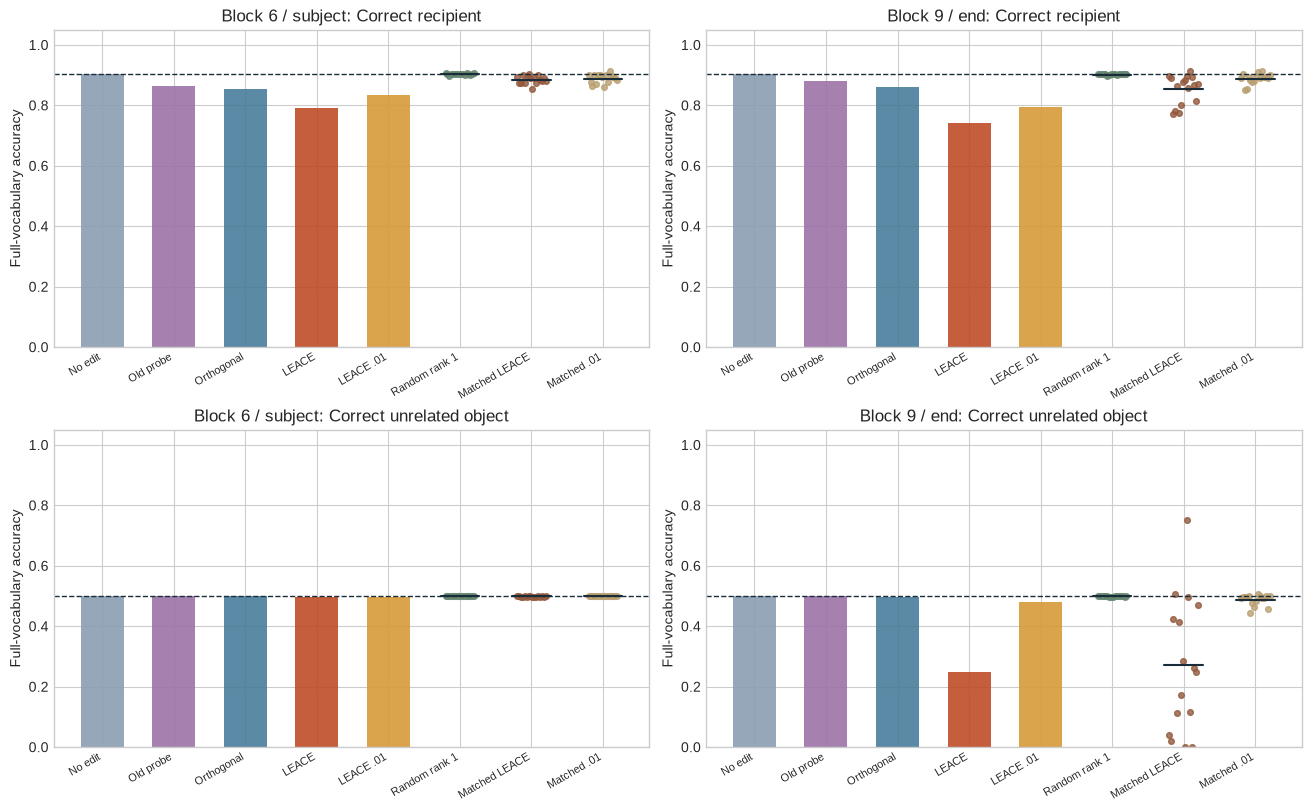

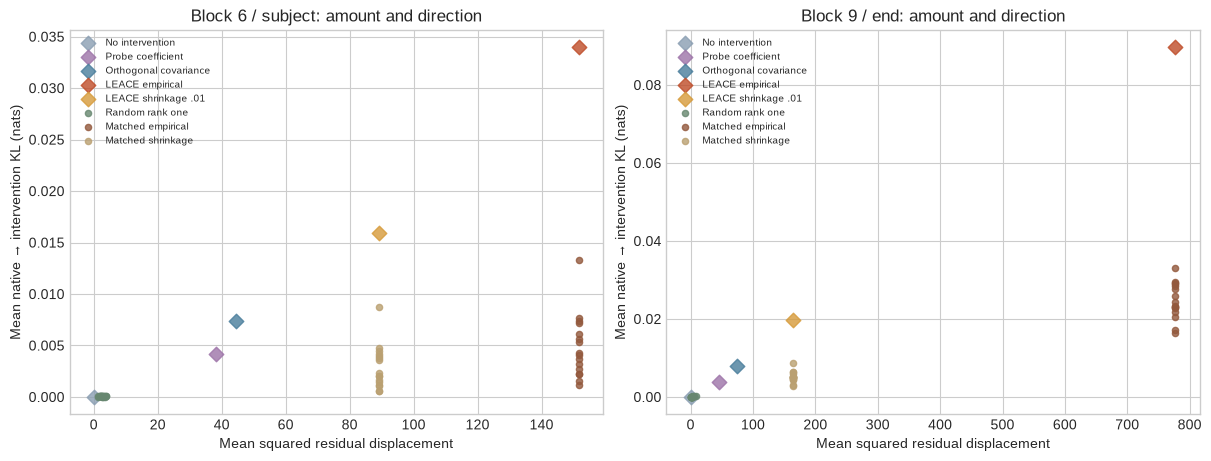

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
for column, (layer, position) in enumerate(protocol.SITES):
    site = f"{layer}/{position}"
    for row_index, (task, label) in enumerate([("final", "Correct recipient"), ("object_final", "Correct unrelated object")]):
        native_accuracy = next(row[task]["accuracy"] for row in final_results if row["site"] == site and row["method"] == "No intervention")
        plot_condition_values(axes[row_index, column], site, lambda row: row[task]["accuracy"], "Full-vocabulary accuracy", f"Block {layer} / {position}: {label}")
        axes[row_index, column].axhline(native_accuracy, color="#182c3a", linestyle="--", linewidth=1)
        axes[row_index, column].set_ylim(0, 1.05)
fig.savefig(assets_dir / "erasure_final_task_and_collateral.png", dpi=160)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for ax, (layer, position) in zip(axes, protocol.SITES):
    site = f"{layer}/{position}"
    for family, color in zip(family_order, family_colors):
        values = [row for row in final_results if row["site"] == site and row["family"] == family]
        ax.scatter([row["final"]["mse"] for row in values], [row["final"]["kl_from_native"] for row in values],
                   color=color, label=family, s=55 if len(values) == 1 else 20, marker="D" if len(values) == 1 else "o", alpha=.8)
    ax.set(xlabel="Mean squared residual displacement", ylabel="Mean native → intervention KL (nats)", title=f"Block {layer} / {position}: amount and direction")
    ax.legend(fontsize=7)
fig.savefig(assets_dir / "erasure_distortion_and_native_kl.png", dpi=160)
plt.show()


## Signature result — see the actual tokens

The examples below are the first final role sentence from each of the three
predeclared templates. Their inclusion is independent of success. At block 9's
final token, compare the original model, the three covariance erasers and the
first matched empirical control. The heatmap has two named-token probabilities
and a third column for all other vocabulary items. The labels show the actual
winning token, which can be outside the pair. Read the displayed prompt and
expected answer before interpreting each row.

In the reference execution, the hotel example changes from Daniel to the
incorrect Mary under empirical LEACE. The other two examples keep Daniel as
the winner while reducing its probability. Thus unchanged top tokens can still
hide substantial distribution changes. The “all others” column aggregates many
tokens; its total can exceed Daniel's probability even when Daniel is the
single most likely token.


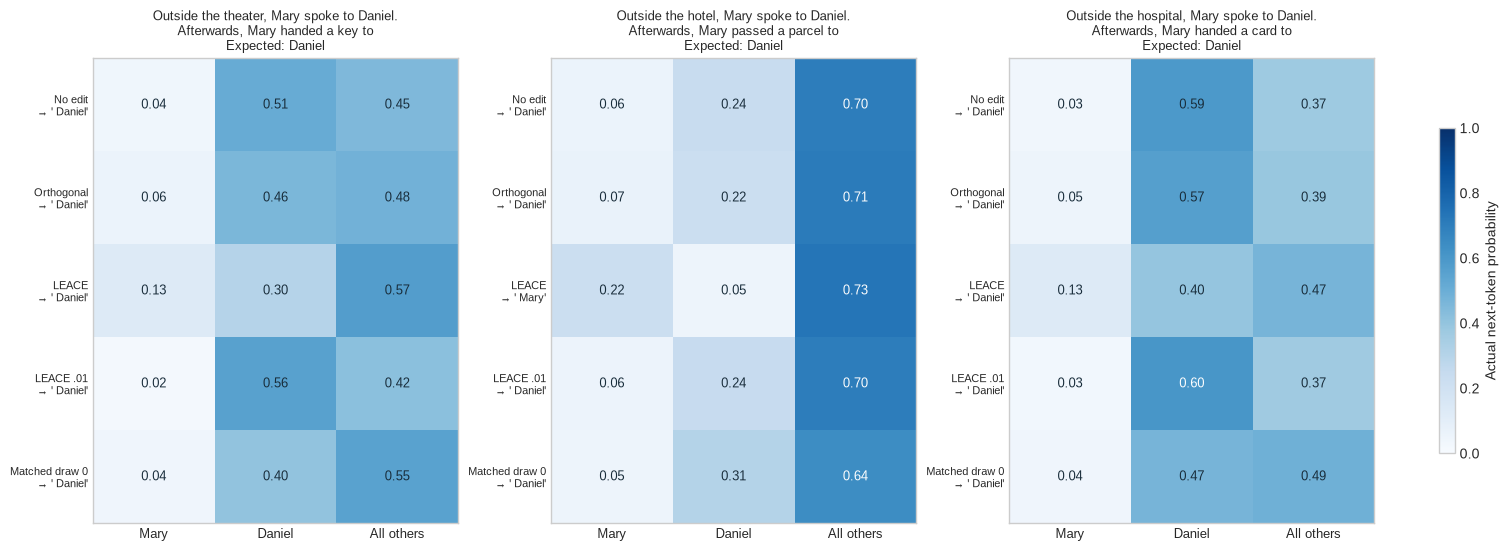

In [23]:
example_indices = [next(index for index, row in enumerate(rows["final"]) if row["template"] == template)
                   for template in range(len(data.MAIN_TEMPLATES["final"]))]
gallery_methods = ["No intervention", "Orthogonal covariance", "LEACE empirical", "LEACE shrinkage .01", "Matched empirical/draw00"]
gallery_data = {}
for name in gallery_methods:
    record = next(row for row in final_results if row["site"] == "9/end" and row["method"] == name)
    # Read one condition at a time; keep only the three displayed rows.
    actual = t.load(assets_dir / record["tensor_file"], weights_only=True)
    gallery_data[name] = actual["final"]["logits"][example_indices].clone()
    del actual
fig, axes = plt.subplots(1, 3, figsize=(15, 5.4), constrained_layout=True)
import textwrap
for column, (ax, index) in enumerate(zip(axes, example_indices)):
    example = rows["final"][index]
    probabilities = t.stack([gallery_data[name][column].softmax(-1) for name in gallery_methods])
    name_columns = probabilities[:, [answer_ids[example["a"]], answer_ids[example["b"]]]]
    matrix = t.cat((name_columns, (1 - name_columns.sum(1))[:, None]), 1)
    im = ax.imshow(matrix, vmin=0, vmax=1, cmap="Blues", aspect="auto")
    winners = [tokenizer.decode([int(gallery_data[name][column].argmax())]) for name in gallery_methods]
    labels = [f"{label}\n→ {winner!r}" for label, winner in zip(["No edit", "Orthogonal", "LEACE", "LEACE .01", "Matched draw 0"], winners)]
    ax.set_yticks(range(len(gallery_methods)), labels, fontsize=8)
    ax.set_xticks(range(3), [example["a"], example["b"], "All others"], fontsize=9)
    ax.set_title(textwrap.fill(example["prompt"], 43) + f"\nExpected: {example['answer']}", fontsize=9)
    ax.grid(False)
    for i in range(len(gallery_methods)):
        for j in range(3):
            ax.text(j, i, f"{float(matrix[i, j]):.2f}", ha="center", va="center", color="white" if matrix[i, j] > .6 else "#182c3a", fontsize=9)
fig.colorbar(im, ax=axes, label="Actual next-token probability", shrink=.7)
fig.savefig(assets_dir / "erasure_actual_token_gallery.png", dpi=160)
plt.show()


## Try It Yourself — follow the intervention continuously

Choose a development example and one of the two fitted sites. Before running,
predict whether moving halfway to the erased vector will move the model's
answer halfway toward the erased answer. Transformers are nonlinear, so a
straight path in residual space need not give a straight probability curve.

Change `PLAY_ROW`, `PLAY_SITE`, or `PLAY_METHOD` and rerun. The random comparison
uses the same per-example displacement at each strength. The zero-strength
point is the native baseline. Try both a correct native case and an original
mistake, then explain why “changed answer” and “damaged answer” differ. This
play uses development sentences and leaves the fitted maps unchanged.


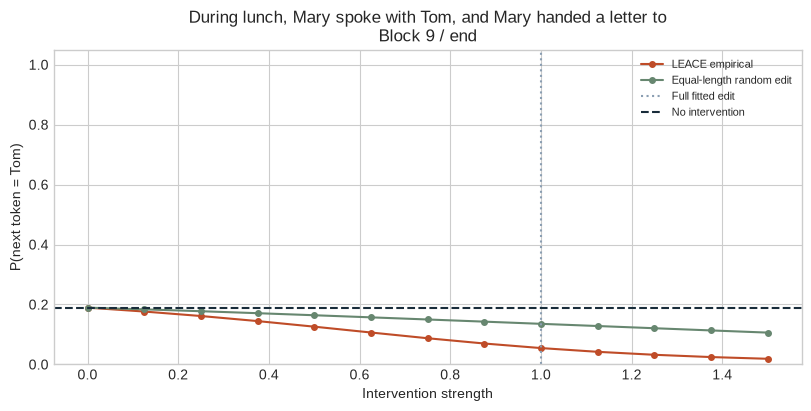

In [24]:
PLAY_ROW = 0
PLAY_SITE = (9, "end")
PLAY_METHOD = "LEACE empirical"
STRENGTHS = np.linspace(0, 1.5, 13)
layer, position = PLAY_SITE
site = f"{layer}/{position}"
play_cache = caches["development"]
example = rows["development"][PLAY_ROW]
base_x = play_cache.activations(layer, position)[PLAY_ROW:PLAY_ROW + 1].double()
condition = condition_bank[site][PLAY_METHOD]
matched_name = "Matched empirical/draw00" if PLAY_METHOD == "LEACE empirical" else "Matched shrinkage/draw00"
assert PLAY_METHOD in ["LEACE empirical", "LEACE shrinkage .01"]
play_curves = {}
with t.no_grad():
    for label, current in [(PLAY_METHOD, condition), ("Equal-length random edit", condition_bank[site][matched_name])]:
        displacement = edit_condition(base_x, current) - base_x
        probabilities = []
        for strength in STRENGTHS:
            replacement = (base_x + strength * displacement).float()
            logits = continue_native(model, play_cache, layer, t.tensor([PLAY_ROW]), replacement, position)
            probabilities.append(float(logits.softmax(-1)[0, answer_ids[example["answer"]]]))
        play_curves[label] = probabilities
fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
for (label, values), color in zip(play_curves.items(), ["#bf4c28", "#678770"]):
    ax.plot(STRENGTHS, values, "o-", markersize=4, label=label, color=color)
ax.axvline(1, color="#8a9eb2", linestyle=":", label="Full fitted edit")
ax.axhline(float(play_cache.logits[PLAY_ROW].softmax(-1)[answer_ids[example["answer"]]]), color="#182c3a", linestyle="--", label="No intervention")
ax.set(xlabel="Intervention strength", ylabel=f"P(next token = {example['answer']})", ylim=(0, 1.05),
       title=textwrap.fill(example["prompt"], 75) + f"\nBlock {layer} / {position}")
ax.legend(fontsize=8)
fig.savefig(assets_dir / "erasure_native_strength_play.png", dpi=160)
plt.show()
assert weight_digest(model) == weights_before


# 5️⃣ What have you learned to claim?

Return to the opening question. A disabled reader, equal class centroids, a
failed new reader, and a changed model answer are four different findings.
You can now construct examples that separate them, implement the affine
constraint and its least-distorting empirical solution, and measure its effect
inside a frozen language model.

The exact four-point example demonstrates why an oblique edit can preserve
useful variation that an orthogonal covariance removal destroys. The equal-mean
counterexample shows why convex-loss guardedness is compatible with nonlinear
information and even a successful hard threshold under 0–1 loss. In GPT-2,
look at the independent reader, native answers and object control together
before describing a concept as removed.

<details>
<summary>Interpretation checklist</summary>

- Did the fitting cross-covariance become zero, and did an independent
  implementation agree with the fitted map?
- Was the evaluated reader refitted after the intervention on separate data?
- Does its log loss improve on a constant predictor, and does its accuracy
  tell the same story?
- Did the model change its actual full-vocabulary answers, including native
  mistakes and answers outside the named pair?
- Are the changes different from random edits of the same rank and magnitude?
- What happened to the unrelated object task?

A positive result on one question does not answer the others.

</details>

## Limitations and further investigations

The native study uses a small pretrained model, finite hand-constructed
sentences and two single-position interventions. The concept is a grammatical
role in these templates, not a complete account of people, identity or meaning.
Empirical class-mean equality is not independence, out-of-distribution erasure,
removal from every token/layer, or a unique causal decomposition. The object
control is one useful side task, not a comprehensive capability benchmark.
The retained random draws describe these controls, not a population uncertainty
estimate.

To go deeper, write down a new hypothesis and new evaluation sentences **before**
measuring their results. Useful directions within this topic include:

- Increase eraser-fitting data while keeping a separate fixed probe-fitting set.
  Predict how empirical rank and new-input distortion will change.
- Fit on shuffled role labels. Inspect whether the fit constraint alone can
  distinguish a meaningful concept from arbitrary labels when width exceeds
  sample count; compare new-sentence reader and native behavior.
- Reproduce the paper's sequential concept-scrubbing procedure. Explain why
  fitting later-layer erasers on untouched activations would be a different
  experiment from fitting after earlier interventions.
- Compare multiple side tasks and an explicit nonlinear readout before making
  a stronger information-removal claim.

These are investigations, not results already established by this notebook.

## Reading

- [Belrose et al., *LEACE: Perfect linear concept erasure in closed form*](https://proceedings.neurips.cc/paper_files/paper/2023/file/d066d21c619d0a78c5b557fa3291a8f4-Paper-Conference.pdf): definitions and Theorems 3.1–4.3 for the guarantee, Appendix E for the singular-covariance construction, and the concept-scrubbing experiments for the gap between single edits and a model-wide intervention.
- [Author implementation at the checked revision](https://github.com/EleutherAI/concept-erasure/tree/9f51753821316a1edacf78b52b464ab26d40e60a): compare its covariance shrinkage and trace-constraint options with the unregularized objective we tested here. The earlier parity cell pins source hashes and states the options explicitly.
- [GPT-2 model card](https://huggingface.co/openai-community/gpt2): the pretrained model used for the native study. The code pins its revision rather than silently switching to a different checkpoint.
